# Notebook 3 — Build a FODO ring

In this first exercise, use the tools introduced in the two introductory notebooks to **build an electron storage ring from identical FODO cells**. Work in this notebook; use the introductory notebooks as references without modifying them.

We will later study the optics and radiation equilibrium of this ring and compare it with a light-source lattice. For now, concentrate on defining the elements, assembling the ring, and checking its geometry.

## Lattice specifications

| Parameter | Value |
|---|---:|
| Reference particle | Electron |
| Reference total energy | 1.7 GeV |
| Ring circumference | 240 m |
| Number of identical FODO cells | 16 |
| Cell length | 15 m |
| Dipoles per cell | 2 |
| Dipole type | Sector bend (`xt.Bend`), with no quadrupole component |
| Dipole length | 3.0 m |
| Quadrupoles per cell | One horizontally focusing QF and one horizontally defocusing QD |
| Quadrupole length | 0.30 m |

## Your tasks

1. **Create an Xtrack environment.** Define variables for the magnet lengths, dipole angle, and two independent quadrupole strengths, `kqf` and `kqd`. Use deferred expressions to connect the elements to these variables. For now, set `kqf = 0.65` m$^{-2}$ and `kqd = -0.65` m$^{-2}$; these are starting values, not matched strengths.
2. **Define the magnets and assemble one FODO cell.** Position the magnets with `env.place(..., at=...)` and let Xtrack create the drifts. Inspect the cell's element table and check its length and element order.
3. **Assemble the ring from 16 copies of the cell.** Give the magnet occurrences unique names with `replace_all_repeated_elements()`, while retaining the common family knobs. Define the 1.7 GeV reference electron for the ring.
4. **Check the geometry.** Verify the circumference, the number of dipoles and quadrupoles, and the total bending angle. Produce a survey plot and check that the end of the ring returns to its starting position and direction, within numerical precision.
5. **Save your lattice for the next exercise.** Store the cell and ring in the environment under the names `cell` and `ring`, then save the environment to `fodo.json`.

At the end of the exercise, your notebook should contain the construction code, numerical geometry checks, and a survey plot. Briefly report the drift length, the angle of each dipole, and its bending radius.

*Optics matching, sextupoles, RF, and radiation are left for subsequent steps.*

## Worked solution

This is one possible layout. We place a dipole halfway between each pair of neighbouring quadrupoles, leaving four equal drifts per cell. The two quadrupole families have independent strength knobs.

### 1. Create the environment and define the parameters

In [1]:
%matplotlib inline
import numpy as np
import xtrack as xt

In [2]:
env = xt.Environment()
env.set_particle_ref('electron', energy0=1.7e9)

n_cells = 16
n_bends = 2 * n_cells

env['l_cell'] = 15.0
env['l_bend'] = 3.0
env['l_quad'] = 0.30
env['angle_bend'] = 2 * np.pi / n_bends
env['l_drift'] = '(l_cell - 2*l_bend - 2*l_quad) / 4'

env['kqf'] = 0.65
env['kqd'] = -0.65

env.vars.get_table()

VarsTable: 8 rows, 3 cols
name               value expr                                                
t_turn_s               0 None                                                
l_cell                15 None                                                
l_bend                 3 None                                                
l_quad               0.3 None                                                
angle_bend       0.19635 None                                                
l_drift              2.1 (((l_cell - (2.0 * l_bend)) - (2.0 * l_quad)) / 4.0)
kqf                 0.65 None                                                
kqd                -0.65 None                                                

Each dipole supplies one thirty-second of a full turn. For a sector bend, `length` is the reference arc length, so its bending radius is the length divided by its angle.

In [3]:
print(f"Drift length: {env['l_drift']:.3f} m")
print(f"Dipole angle: {np.degrees(env['angle_bend']):.3f} degrees")
print(f"Bending radius: {env['l_bend'] / env['angle_bend']:.3f} m")

Drift length: 2.100 m
Dipole angle: 11.250 degrees
Bending radius: 15.279 m


### 2. Define the magnets and build the cell

Use deferred expressions for the lengths, angle, and quadrupole strengths. The dipoles have no quadrupole gradient (`k1 = 0`).

The positions below refer to magnet centres. Place QF half a quadrupole length from the start, then space the magnet centres by a quarter-cell. Specifying the total cell length also creates the final drift automatically.

In [4]:
env.new('qf', xt.Quadrupole, length='l_quad', k1='kqf')
env.new('qd', xt.Quadrupole, length='l_quad', k1='kqd')
env.new('bend', xt.Bend, length='l_bend', angle='angle_bend', k1=0)

cell = env.new_line(name='cell', length=env['l_cell'], components=[
    env.place('qf',   at='l_quad/2'),
    env.place('bend', at='l_quad/2 + l_cell/4'),
    env.place('qd',   at='l_quad/2 + l_cell/2'),
    env.place('bend', at='l_quad/2 + 3*l_cell/4'),
])

np.testing.assert_allclose(cell.get_length(), 15.0, atol=1e-12, rtol=0)
cell.get_table().cols['element_type s_start s_center s_end']

LineTable: 9 rows, 5 cols
name         element_type       s_start      s_center         s_end
qf           Quadrupole               0          0.15           0.3
||drift_1    Drift                  0.3          1.35           2.4
bend::0      Bend                   2.4           3.9           5.4
||drift_2::0 Drift                  5.4          6.45           7.5
qd           Quadrupole             7.5          7.65           7.8
||drift_3    Drift                  7.8          8.85           9.9
bend::1      Bend                   9.9          11.4          12.9
||drift_2::1 Drift                 12.9         13.95            15
_end_point                           15            15            15

### 3. Assemble the ring

Repeat the cell 16 times, then give each magnet occurrence a unique name. The magnets remain linked to the same family variables. Store the ring in the environment alongside the cell.

In [5]:
ring = n_cells * cell
ring.replace_all_repeated_elements()
env['ring'] = ring

print(f"Reference energy: {ring.particle_ref.energy0[0] / 1e9:.3f} GeV")
print(f"Circumference: {ring.get_length():.3f} m")
ring.get_table().cols['element_type s_start s_center s_end']

Reference energy: 1.700 GeV
Circumference: 240.000 m


LineTable: 129 rows, 5 cols
name      element_type       s_start      s_center         s_end
qf.0      Quadrupole               0          0.15           0.3
drift_1.0 Drift                  0.3          1.35           2.4
bend.0    Bend                   2.4           3.9           5.4
drift_2.0 Drift                  5.4          6.45           7.5
qd.0      Quadrupole             7.5          7.65           7.8
drift_3.0 Drift                  7.8          8.85           9.9
bend.1    Bend                   9.9          11.4          12.9
drift_2.1 Drift                 12.9         13.95            15
qf.1      Quadrupole              15         15.15          15.3
drift_1.1 Drift                 15.3         16.35          17.4
...
drift_2.29 Drift                222.9        223.95           225
qf.15      Quadrupole             225        225.15         225.3
drift_1.15 Drift                225.3        226.35         227.4
bend.30    Bend                 227.4         228.9    

### 4. Check the element counts and bending angle

Use the assembled ring's element table to check what was actually built. There should be 32 dipoles and 32 quadrupoles.

In [6]:
tt = ring.get_table(attr=True)
is_bend = tt.element_type == 'Bend'
is_quad = tt.element_type == 'Quadrupole'

total_bending_angle = np.sum(tt.angle[is_bend])
assert np.count_nonzero(is_bend) == 32
assert np.count_nonzero(is_quad) == 32
np.testing.assert_allclose(ring.get_length(), 240.0, atol=1e-10, rtol=0)
np.testing.assert_allclose(total_bending_angle, 2 * np.pi, atol=1e-12, rtol=0)

# Verify that every occurrence has its family's specified strength.
for name in tt.name[is_quad]:
    family_knob = 'kqf' if name.startswith('qf') else 'kqd'
    np.testing.assert_allclose(ring[name].k1, env[family_knob])

print(f'Dipoles: {np.count_nonzero(is_bend)}')
print(f'Quadrupoles: {np.count_nonzero(is_quad)}')
print(f'Total bending angle: {np.degrees(total_bending_angle):.3f} degrees')

Dipoles: 32
Quadrupoles: 32
Total bending angle: 360.000 degrees


### 5. Check survey closure and plot the ring

A total bend of $2\pi$ is a necessary check, but also verify that the end position coincides with the start. The survey angle `theta` accumulates a full turn; compare the initial and final orientations modulo $2\pi$.

Position closure error: 3.56e-14 m
Largest orientation error: 2.45e-16 rad


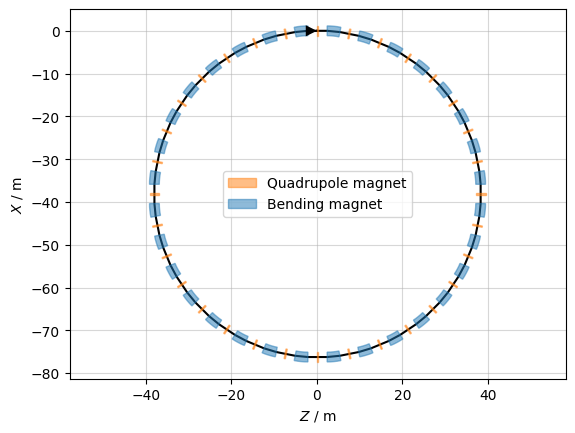

In [7]:
sv = ring.survey()
position_error = np.array([
    sv.X[-1] - sv.X[0],
    sv.Y[-1] - sv.Y[0],
    sv.Z[-1] - sv.Z[0],
])
angle_changes = np.array([
    sv.theta[-1] - sv.theta[0],
    sv.phi[-1] - sv.phi[0],
    sv.psi[-1] - sv.psi[0],
])
# Wrap each angle to [-pi, pi] for this planar ring.
orientation_error = np.arctan2(np.sin(angle_changes), np.cos(angle_changes))

np.testing.assert_allclose(position_error, 0, atol=1e-9, rtol=0)
np.testing.assert_allclose(orientation_error, 0, atol=1e-10, rtol=0)
print(f'Position closure error: {np.linalg.norm(position_error):.2e} m')
print(f'Largest orientation error: {np.max(np.abs(orientation_error)):.2e} rad')

sv.plot()

### 6. Save the lattice

The environment contains the named `cell` and `ring`, their elements, the reference particle, and the variables controlling the magnets. Save these together for the next exercise.

In [8]:
env.to_json('fodo.json')
print('Saved cell and ring to fodo.json')

Saved cell and ring to fodo.json


The ring geometry is now complete: 2.10 m drifts, 11.25° dipoles, and a bending radius of approximately 15.28 m. The quadrupole strengths are still the initial guesses. We will calculate and match the optics in the next step.